# Enron email corpus — exploratory analysis

Works on the corpus built by `jevron ingest` from the CMU release (`enron_mail_20150507.tar.gz`):

- `data/emails.parquet`: one row per distinct email (255,170), with `n_copies` and `mailboxes`
- `data/locations.parquet`: one row per original message file (517,401), giving its mailbox and folder

Parsing, encoding handling and deduplication live in `jevron.corpus`, which this notebook shares
with the CLI and the browser. If the files are missing, the first cell builds them (about 1–2 minutes).

In [1]:
from collections import Counter
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

from jevron import corpus

pd.set_option("display.max_colwidth", 80)

TARBALL = corpus.DEFAULT_TARBALL      # ~/Downloads/enron_mail_20150507.tar.gz
DATA_DIR = Path("data")

## 1. Load the corpus

In [2]:
if not (corpus.emails_path(DATA_DIR).exists() and corpus.locations_path(DATA_DIR).exists()):
    print(f"Building the corpus from {TARBALL} (same as `jevron ingest`) ...")
    corpus.build(TARBALL, DATA_DIR)

emails = corpus.load(DATA_DIR)
locations = corpus.load_locations(DATA_DIR)
emails["n_recipients"] = emails["to"].str.len() + emails["cc"].str.len() + emails["bcc"].str.len()
emails["body_len"] = emails["body"].str.len()
print(f"{len(emails):,} distinct emails from {len(locations):,} files in {locations['user'].nunique()} mailboxes")
emails.head()

255,170 distinct emails from 517,401 files in 150 mailboxes


,message_id,date,from,to,cc,bcc,subject,x_from,user,folder,body,path,n_copies,mailboxes,n_recipients,body_len
0,<32467700.1075846198563.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,steven.kean@enron.com,[],[],[],california energy prices,Steven J Kean,kean-s,all_documents,Summary of what we discussed the other night:\n\nBackground:\n\n\npower -- p...,data/raw/maildir/kean-s/all_documents/2141.,4,[kean-s],0,1365
1,<33385514.1075854437036.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,kay.chapman@enron.com,"[tim.belden@enron.com, kevin.presto@enron.com, john.arnold@enron.com, scott....","[patti.thompson@enron.com, mollie.gustafson@enron.com, felicia.doan@enron.co...","[patti.thompson@enron.com, mollie.gustafson@enron.com, felicia.doan@enron.co...",ENA Management Committee,Kay Chapman,delainey-d,all_documents,"\n The Friday September 1, 2000 ENA Management Committee Meeting has been \...",data/raw/maildir/delainey-d/all_documents/362.,2,[delainey-d],61,2193
2,<25323182.1075854432336.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,kay.chapman@enron.com,"[david.w.delainey@enron.com, lavorato@enron.com, tim.belden@enron.com, derek...","[kay.chapman@enron.com, kimberly.hillis@enron.com, angela.mcculloch@enron.co...","[kay.chapman@enron.com, kimberly.hillis@enron.com, angela.mcculloch@enron.co...",2000 ENA Vegas Offsite,Kay Chapman,delainey-d,all_documents,Attached please find the invitation for the Las Vegas Offsite to be held at ...,data/raw/maildir/delainey-d/all_documents/160.,2,[delainey-d],121,265
3,<11039522.1075848306657.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,david.delainey@enron.com,[kay.chapman@enron.com],[],[],ENA 2000 Offsite,David W Delainey,delainey-d,all_documents,Given tremendous energy market volatility and as we stretch resources to mak...,data/raw/maildir/delainey-d/all_documents/1.,2,[delainey-d],1,304
4,<13564084.1075846659497.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,susan.scott@enron.com,[],[],[],,Susan Scott,scott-s,all_documents,Koch Gateway has a provision in the Negotiated Rates section of its tariff \...,data/raw/maildir/scott-s/all_documents/123.,2,[scott-s],0,1090


## 2. Duplicates

The same message often appears in several folders (`sent`, `sent_items`, `_sent_mail`, `all_documents`, …) and in several users' mailboxes.
`jevron ingest` deduplicates on (sender, date, subject, body) and records how many files held each email.

In [3]:
print(f"{len(locations):,} files -> {len(emails):,} distinct emails ({1 - len(emails) / len(locations):.0%} duplicates)")
emails["n_copies"].value_counts().sort_index().head(10).rename("emails").to_frame().T

517,401 files -> 255,170 distinct emails (51% duplicates)


n_copies,1,2,3,4,5,6,7,8,9,10
emails,124193,62413,39129,20721,3034,2688,738,523,654,159


## 3. Volume over time

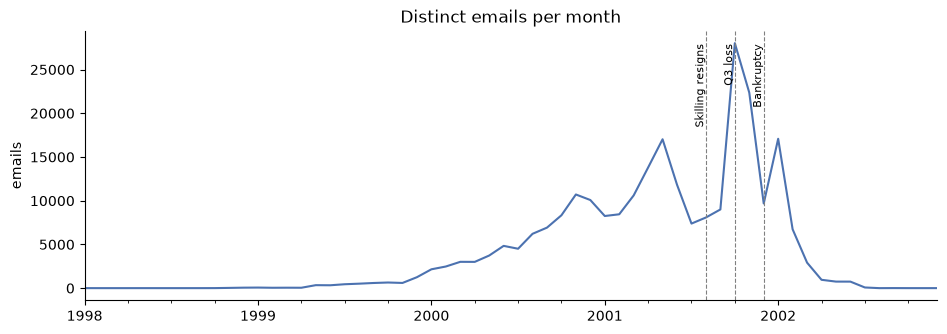

In [4]:
# A handful of messages carry bogus dates (1979, 2044, ...); keep the real window.
emails = emails[(emails["date"] >= "1998-01-01") & (emails["date"] < "2003-01-01")]

monthly = emails.set_index("date").resample("MS").size()
ax = monthly.plot(figsize=(11, 3.5), color="#4C72B0")
ax.set(title="Distinct emails per month", xlabel="", ylabel="emails")
for d, label in [("2001-08-14", "Skilling resigns"), ("2001-10-16", "Q3 loss"), ("2001-12-02", "Bankruptcy")]:
    ax.axvline(pd.Timestamp(d, tz="UTC"), color="gray", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d, tz="UTC"), ax.get_ylim()[1] * 0.95, label, rotation=90, va="top", ha="right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

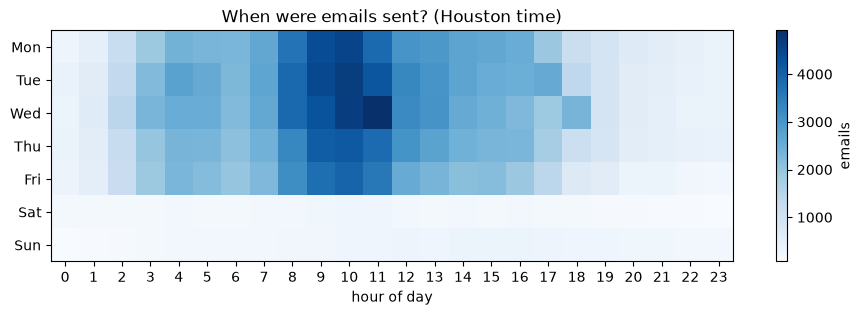

In [5]:
local = emails["date"].dt.tz_convert("US/Central")  # Enron HQ was in Houston
heat = pd.crosstab(local.dt.day_of_week, local.dt.hour).reindex(index=range(7), columns=range(24), fill_value=0)
heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_yticks(range(7)); ax.set_yticklabels(heat.index)
ax.set(title="When were emails sent? (Houston time)", xlabel="hour of day")
fig.colorbar(im, ax=ax, label="emails")
plt.show()

## 4. Who sends and receives the most

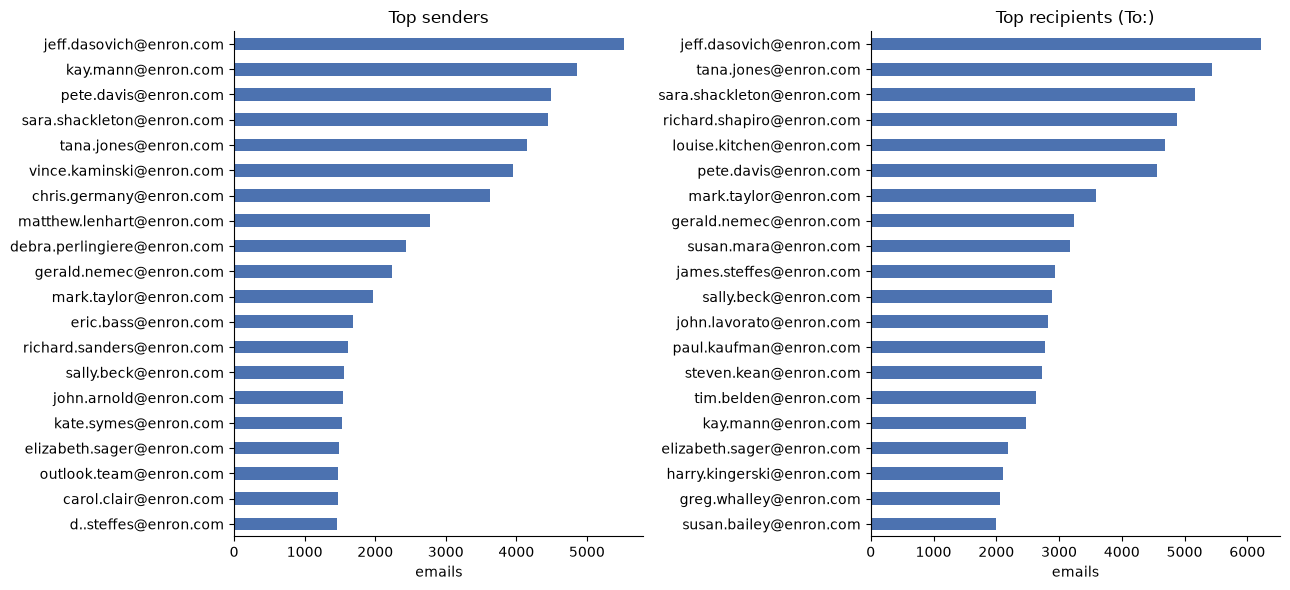

In [6]:
top_senders = emails["from"].value_counts().head(20)
top_recipients = emails.explode("to")["to"].value_counts().head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, s, title in [(axes[0], top_senders, "Top senders"), (axes[1], top_recipients, "Top recipients (To:)")]:
    s.sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set(title=title, xlabel="emails", ylabel="")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
is_internal = lambda a: isinstance(a, str) and a.endswith("@enron.com")
print(f"Sent from @enron.com: {emails['from'].map(is_internal).mean():.1%}")
domains = emails["from"].dropna().str.split("@").str[-1].value_counts().head(15)
domains

Sent from @enron.com: 77.8%


from
enron.com                      198118
aol.com                          1773
hotmail.com                      1690
mailman.enron.com                1258
yahoo.com                         970
ccomad3.uu.commissioner.com       783
nymex.com                         776
haas.berkeley.edu                 734
txu.com                           683
caiso.com                         548
carrfut.com                       522
concureworkplace.com              521
nyiso.com                         514
williams.com                      475
earthlink.net                     448
Name: count, dtype: int64

## 5. Mailboxes and folders

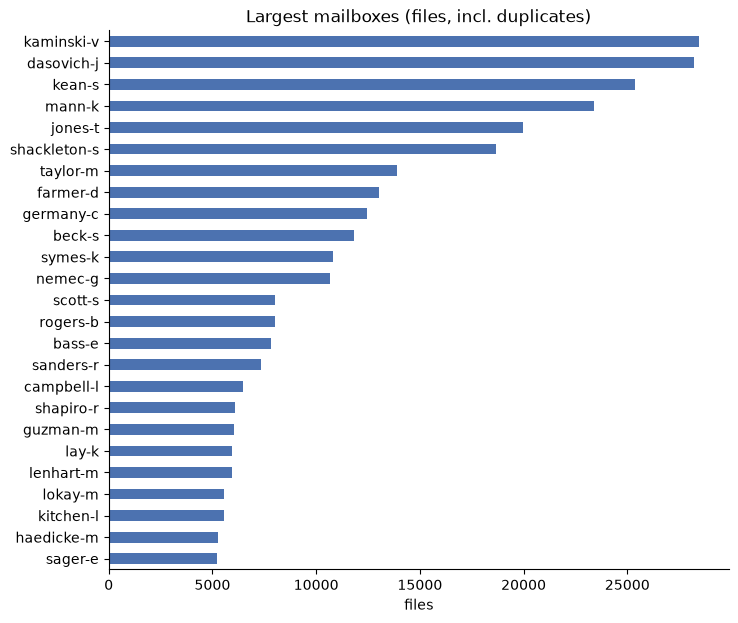

folder
all_documents          128103
discussion_threads      58609
sent                    57653
deleted_items           51356
inbox                   44859
sent_items              37921
notes_inbox             36665
_sent_mail              30109
calendar                 6133
archiving                4477
_americas                4021
personal                 2577
attachments              2026
meetings                 1872
c                        1656
schedule_crawler         1398
chris_stokley            1252
logistics                1192
archive                  1179
tw_commercial_group      1159
Name: count, dtype: int64

In [8]:
per_user = locations.groupby("user").size().sort_values(ascending=False)
ax = per_user.head(25).sort_values().plot.barh(figsize=(8, 7), color="#4C72B0")
ax.set(title="Largest mailboxes (files, incl. duplicates)", xlabel="files", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

locations["folder"].str.split("/").str[0].value_counts().head(20)

## 6. Communication network (who emails whom)

In [9]:
edges = (
    emails.explode("to")
    .dropna(subset=["from", "to"])
    .query("`from` != to")
    .groupby(["from", "to"]).size()
    .rename("n").sort_values(ascending=False)
    .reset_index()
)
print(f"{len(edges):,} distinct sender->recipient pairs")
edges.head(25)

308,577 distinct sender->recipient pairs


,from,to,n
0,vince.kaminski@enron.com,vkaminski@aol.com,1141
1,jeff.dasovich@enron.com,susan.mara@enron.com,934
2,jeff.dasovich@enron.com,paul.kaufman@enron.com,877
3,jeff.dasovich@enron.com,richard.shapiro@enron.com,863
4,jeff.dasovich@enron.com,james.steffes@enron.com,780
5,jeff.dasovich@enron.com,karen.denne@enron.com,724
6,jeff.dasovich@enron.com,harry.kingerski@enron.com,546
7,jeff.dasovich@enron.com,skean@enron.com,528
8,jeff.dasovich@enron.com,sandra.mccubbin@enron.com,499
9,michelle.nelson@enron.com,mike.maggi@enron.com,494


## 7. Message content

count     254687.0
mean        1864.0
std         8905.0
min            1.0
25%          283.0
50%          766.0
75%         1765.0
max      2011422.0
Name: body_len, dtype: float64


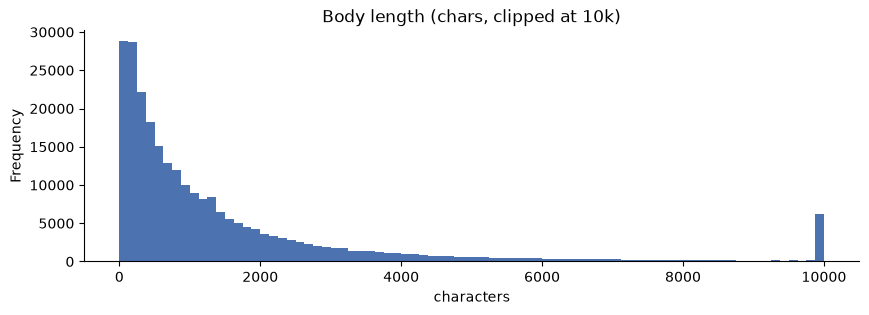

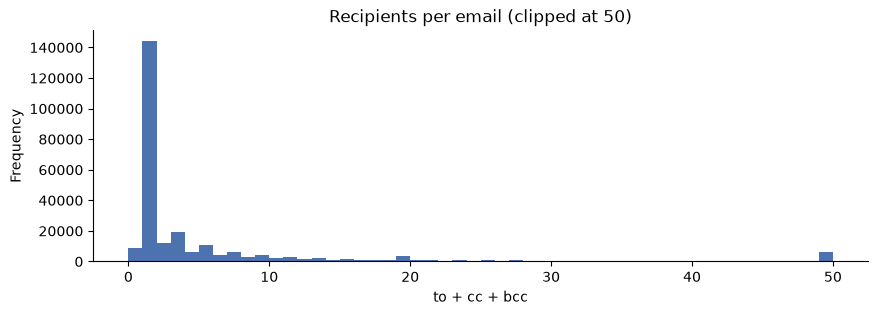

In [10]:
print(emails["body_len"].describe().round(0))
ax = emails["body_len"].clip(upper=10_000).plot.hist(bins=80, figsize=(10, 3), color="#4C72B0")
ax.set(title="Body length (chars, clipped at 10k)", xlabel="characters")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

ax = emails["n_recipients"].clip(upper=50).plot.hist(bins=50, figsize=(10, 3), color="#4C72B0")
ax.set(title="Recipients per email (clipped at 50)", xlabel="to + cc + bcc")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [11]:
STOP = set("""re fw fwd the a an and or of to for in on at is with from by your you our we this that
it be are as - & : / meeting update""".split())
words = Counter(
    w for s in emails["subject"].str.lower()
    for w in re.findall(r"[a-z][a-z']+", s) if w not in STOP and len(w) > 2
)
pd.Series(dict(words.most_common(30))).to_frame("count").T

,enron,gas,new,agreement,energy,power,com,report,request,hourahead,...,trading,access,draft,daily,revised,news,list,california,market,day
count,10799,5895,5848,5243,5099,4988,4875,4646,4517,4417,...,2470,2452,2437,2360,2274,2254,2247,2245,2191,1979


In [12]:
def search(term, n=10):
    """Case-insensitive search over subject + body (same matching as `jevron emails --search`)."""
    hits = corpus.filter_emails(emails, search=term)
    print(f"{len(hits):,} emails mention {term!r}")
    return hits[["date", "from", "subject"]].sort_values("date").head(n)

search("raptor")

409 emails mention 'raptor'


,date,from,subject
14123,2000-04-12 16:22:00+00:00,paulo.issler@enron.com,Talon
16331,2000-05-02 18:33:00+00:00,carol.clair@enron.com,Project Raptor
16332,2000-05-02 18:38:00+00:00,carol.clair@enron.com,Project Raptor
17377,2000-05-11 13:37:00+00:00,david.delainey@enron.com,Re: Raptor
17387,2000-05-11 14:32:00+00:00,david.delainey@enron.com,Re: Raptor
17410,2000-05-11 15:44:00+00:00,david.delainey@enron.com,Re: Raptor
19657,2000-05-31 11:24:00+00:00,eric.bass@enron.com,Re: ESPN.com - College Basketball - Draft: Mihm stands tall at No.\n 1
20810,2000-06-08 10:00:00+00:00,carol.clair@enron.com,Raptor Dinner
21940,2000-06-15 15:21:00+00:00,carol.clair@enron.com,Raptor 2
22483,2000-06-20 11:09:00+00:00,carol.clair@enron.com,raptor II


## 8. Hand-labeled subset (UC Berkeley)

The [UC Berkeley Enron Email Analysis project](https://bailando.berkeley.edu/enron_email.html) hand-labeled about 1,700 emails with categories in four groups: coarse genre, included or forwarded content, primary topic (for business email) and emotional tone. Each email was labeled by two people. A label's `annotators` value says how many of them chose it.

The project chose emails focused on business, the California energy crisis and later messages, and avoided very personal emails and jokes. It makes no claims about how consistent its labels are. Both points matter if these labels become a benchmark for Jev.

`jevron.berkeley.load` extracts `~/Downloads/enron_with_categories.tar.gz` into `data/berkeley/` the first time. It links each labeled file to the corpus on the same fields ingest deduplicates on (sender, date, subject, body).

In [13]:
from jevron import berkeley

labels = berkeley.load(DATA_DIR)
GROUP_ORDER = ["coarse genre", "included/forwarded", "topic", "emotional tone"]
print(f"{labels['berkeley_id'].nunique():,} labeled files -> {labels['message_id'].nunique():,} distinct corpus emails, "
      f"{len(labels):,} labels")
(labels.groupby("group_name")
       .agg(files=("berkeley_id", "nunique"), labels=("code", "size"))
       .reindex(GROUP_ORDER))

1,702 labeled files -> 1,658 distinct corpus emails, 5,750 labels


,files,labels
group_name,,
coarse genre,1702,1925
included/forwarded,1282,2231
topic,879,1216
emotional tone,310,378


### 8.1 Category frequencies

The number of labeled files each category was assigned to, by at least one annotator.

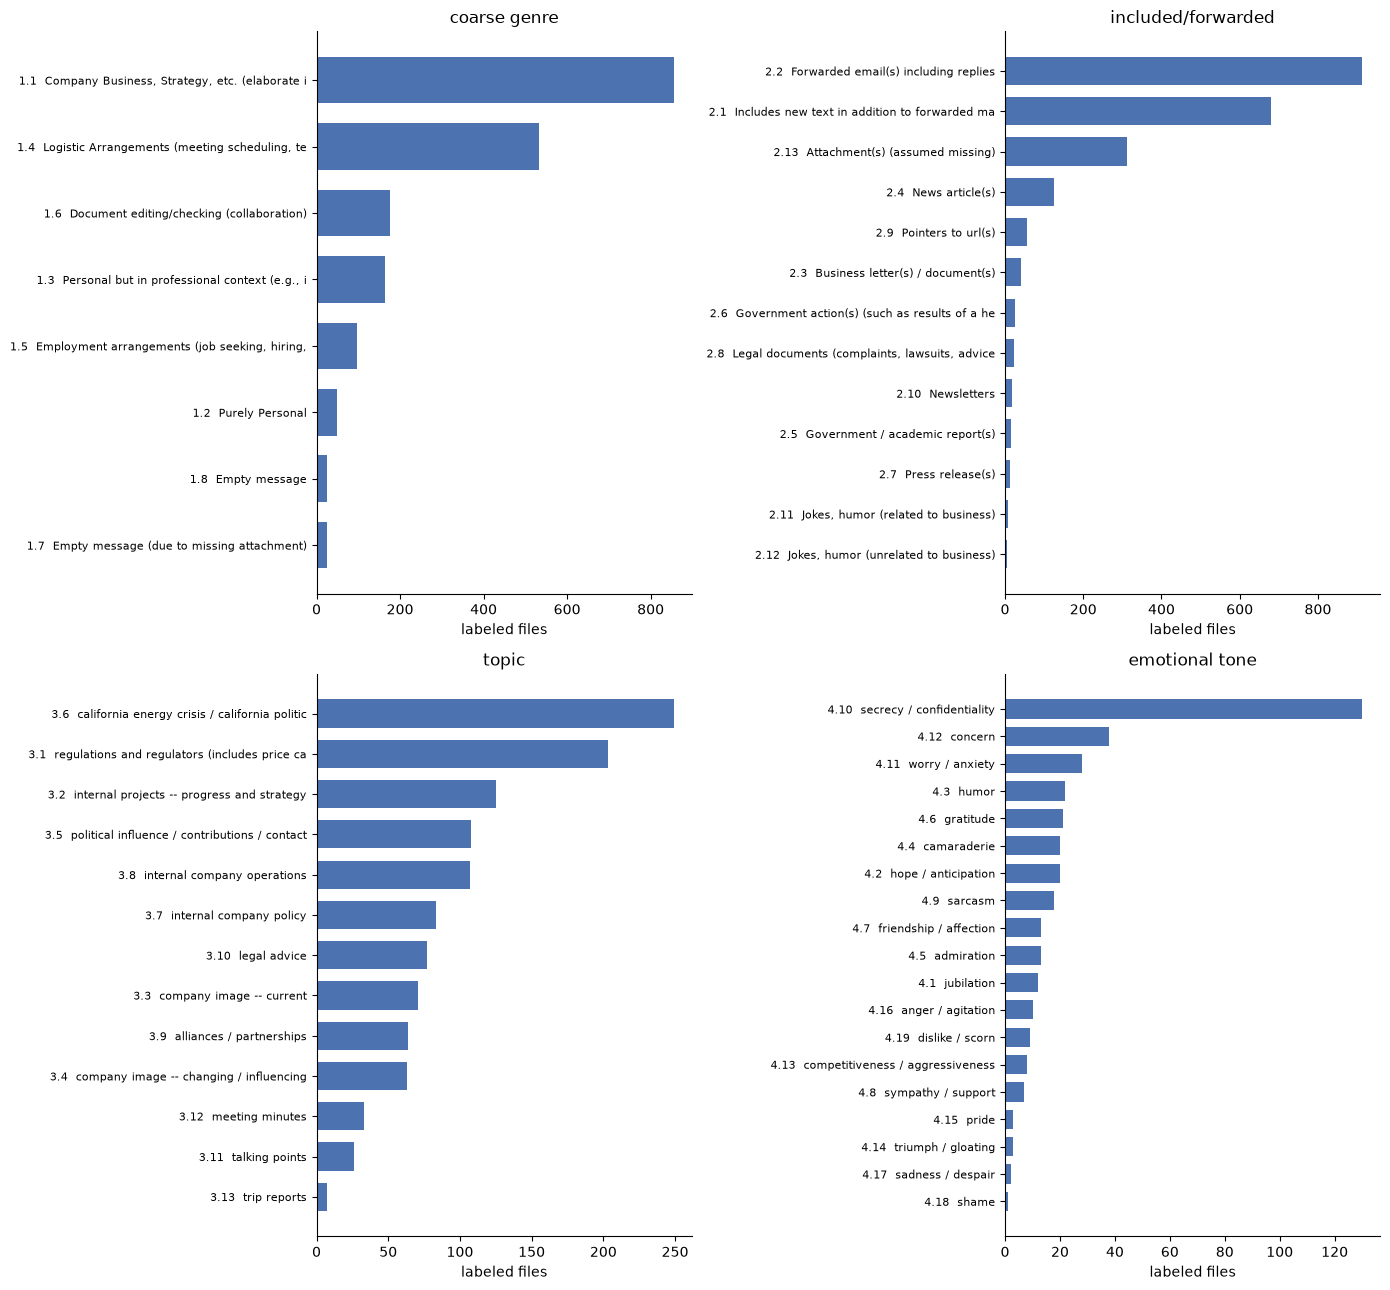

In [14]:
per_category = (labels.groupby(["group_name", "code", "name"])["berkeley_id"].nunique()
                      .rename("files").reset_index())

fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for ax, group in zip(axes.flat, GROUP_ORDER):
    data = per_category[per_category["group_name"] == group].sort_values("files")
    ax.barh(data["code"] + "  " + data["name"].str.slice(0, 45), data["files"], color="#4C72B0", height=0.7)
    ax.set(title=group, xlabel="labeled files")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### 8.2 Annotator agreement

With two annotators per email, `annotators == 1` means only one of them chose the category, and 2 or more means both did. A handful of labels have 3 or 4 (`annotators` goes up to 4), so some emails had more than two annotators. The share of a category's assignments that both annotators chose is a rough agreement rate. Categories with low agreement make noisy benchmarks, for people and for Jev alike.

In [15]:
agreement = (labels.assign(agreed=labels["annotators"] >= 2)
                   .groupby(["group_name", "code", "name"])
                   .agg(assigned=("agreed", "size"), agreed=("agreed", "sum"))
                   .reset_index())
agreement["agreement"] = agreement["agreed"] / agreement["assigned"]

by_group = agreement.groupby("group_name")[["assigned", "agreed"]].sum().reindex(GROUP_ORDER)
by_group["agreement"] = (by_group["agreed"] / by_group["assigned"]).map("{:.0%}".format)
by_group

,assigned,agreed,agreement
group_name,,,
coarse genre,1925,1231,64%
included/forwarded,2231,1229,55%
topic,1216,637,52%
emotional tone,378,191,51%


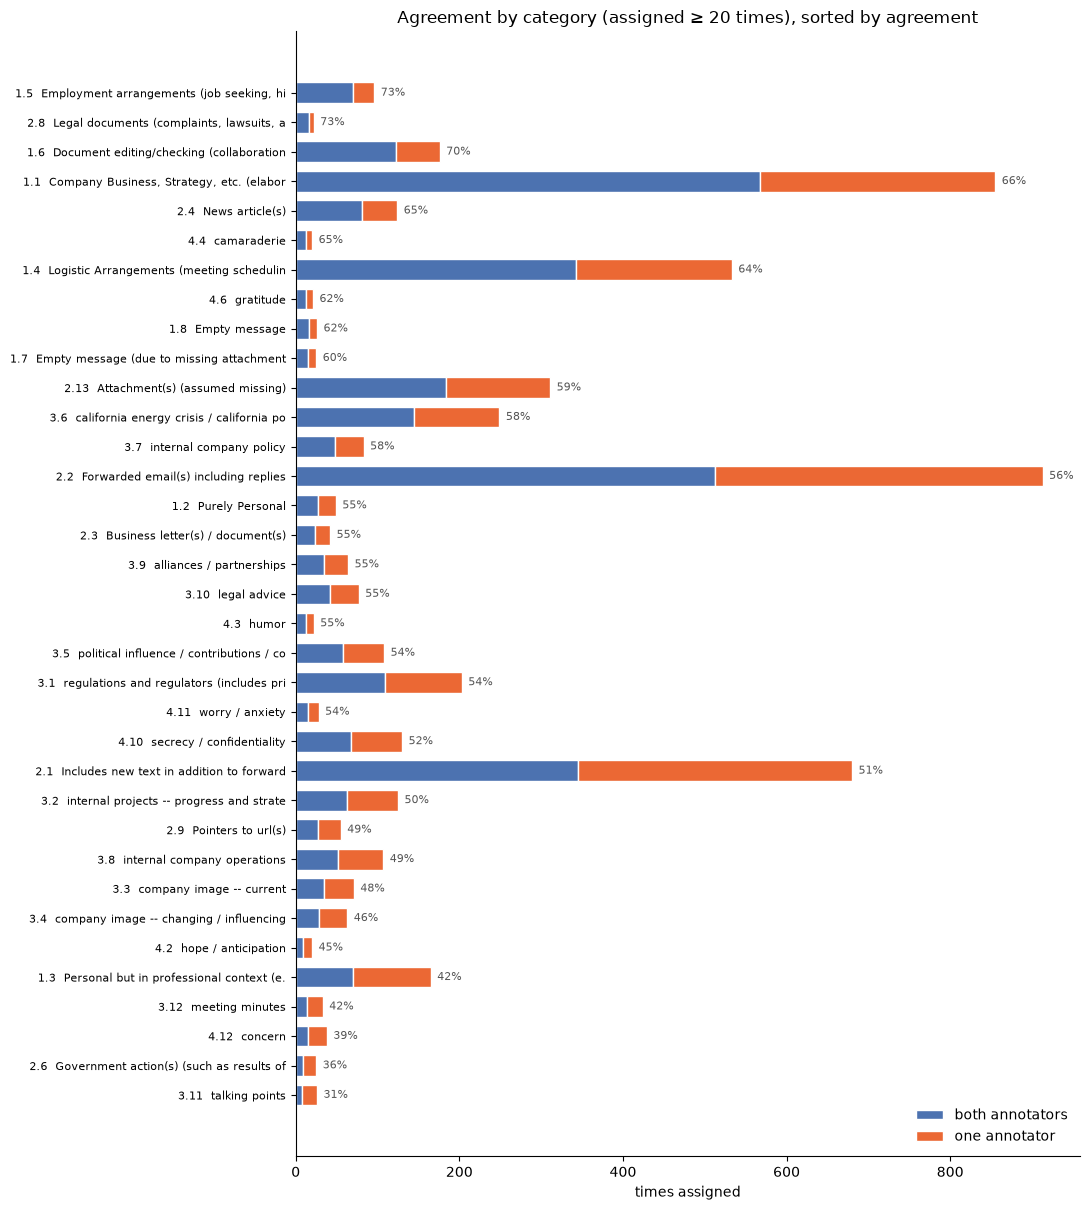

In [16]:
# Categories assigned at least 20 times, sorted by agreement. Stacked bars: chosen by one annotator vs both.
shown = agreement[agreement["assigned"] >= 20].sort_values("agreement")
labels_y = shown["code"] + "  " + shown["name"].str.slice(0, 40)

fig, ax = plt.subplots(figsize=(11, 0.32 * len(shown) + 1))
ax.barh(labels_y, shown["agreed"], color="#4C72B0", height=0.7, label="both annotators", edgecolor="white", linewidth=1)
ax.barh(labels_y, shown["assigned"] - shown["agreed"], left=shown["agreed"], color="#eb6834", height=0.7,
        label="one annotator", edgecolor="white", linewidth=1)
for y, (n, rate) in enumerate(zip(shown["assigned"], shown["agreement"])):
    ax.text(n + 8, y, f"{rate:.0%}", va="center", fontsize=8, color="#555555")
ax.set(title="Agreement by category (assigned ≥ 20 times), sorted by agreement", xlabel="times assigned")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [17]:
# Coarse genre is meant to be a single choice. Files with two or more genres are disagreements on the genre itself.
genres_per_file = labels[labels["group"] == 1].groupby("berkeley_id")["code"].nunique()
genres_per_file.value_counts().sort_index().rename("files").rename_axis("coarse genres per file").to_frame().T

coarse genres per file,1,2,3
files,1495,191,16


### 8.3 The same email, labeled more than once

Some identical emails, for example a news digest sent to many mailboxes, were labeled several times under different Berkeley IDs. Comparing the label sets shows how consistent the labels are when the input is exactly the same.

In [18]:
sets = (labels.groupby(["message_id", "berkeley_id"])["code"]
              .agg(lambda codes: ", ".join(sorted(codes, key=lambda c: tuple(map(int, c.split("."))))))
              .rename("codes").reset_index())
repeated = sets.groupby("message_id").filter(lambda g: len(g) > 1)
summary = repeated.groupby("message_id").agg(files=("berkeley_id", "size"), distinct_label_sets=("codes", "nunique"))
print(f"{len(summary)} emails were labeled in {summary['files'].sum()} files; "
      f"{(summary['distinct_label_sets'] > 1).sum()} of them got different label sets across copies")
example = summary.sort_values("files").index[-1]
print(f"\nMost-repeated: {emails.set_index('message_id').loc[example, 'subject']!r}")
repeated[repeated["message_id"] == example][["berkeley_id", "codes"]]

20 emails were labeled in 64 files; 20 of them got different label sets across copies

Most-repeated: 'Energy Issues'


,berkeley_id,codes
912,124030,"1.1, 2.4, 3.6"
913,125725,"1.1, 2.4, 3.1, 3.6"
914,175091,"1.1, 2.4, 3.6"
915,176751,"1.1, 2.4, 3.6"
916,176828,"1.1, 2.4, 3.6"
917,177003,"1.1, 2.4, 3.1, 3.6"
918,177235,"1.1, 2.4, 3.6"


### 8.4 How the labeled subset differs from the whole corpus

The subset was hand-picked, so it doesn't represent the corpus. The charts compare when its emails were sent and whose mailboxes they came from.

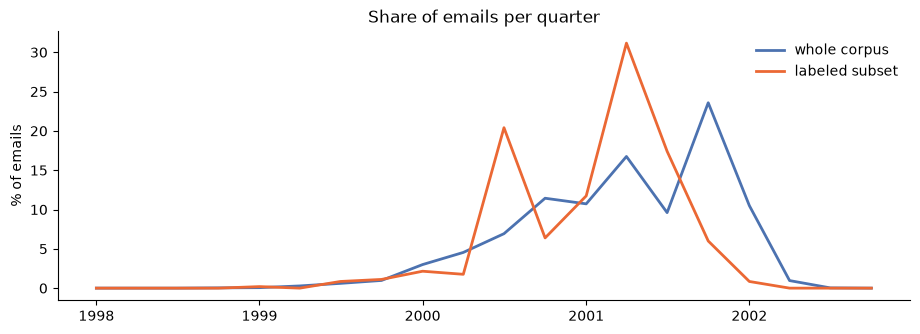

,labeled subset,whole corpus
user,,
kean-s,56.3%,2.0%
kaminski-v,12.5%,4.4%
dasovich-j,9.0%,6.2%
shapiro-r,3.3%,1.0%
sanders-r,3.0%,1.5%
steffes-j,1.8%,1.0%
cash-m,1.7%,0.9%
skilling-j,1.5%,0.9%
hayslett-r,0.7%,0.6%


In [19]:
labeled = emails[emails["message_id"].isin(labels["message_id"])]
share = pd.DataFrame({
    "whole corpus": emails.set_index("date").resample("QS").size(),
    "labeled subset": labeled.set_index("date").resample("QS").size(),
}).fillna(0)
share = share / share.sum()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(share.index, share["whole corpus"] * 100, color="#4C72B0", lw=2, label="whole corpus")
ax.plot(share.index, share["labeled subset"] * 100, color="#eb6834", lw=2, label="labeled subset")
ax.set(title="Share of emails per quarter", ylabel="% of emails", xlabel="")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

top_users = pd.DataFrame({
    "labeled subset": labeled["user"].value_counts(normalize=True),
    "whole corpus": emails["user"].value_counts(normalize=True),
}).fillna(0).sort_values("labeled subset", ascending=False).head(10)
top_users.map("{:.1%}".format)

### 8.5 Topics and emotional tone

How often each tone appears together with each topic, counted in labeled files.

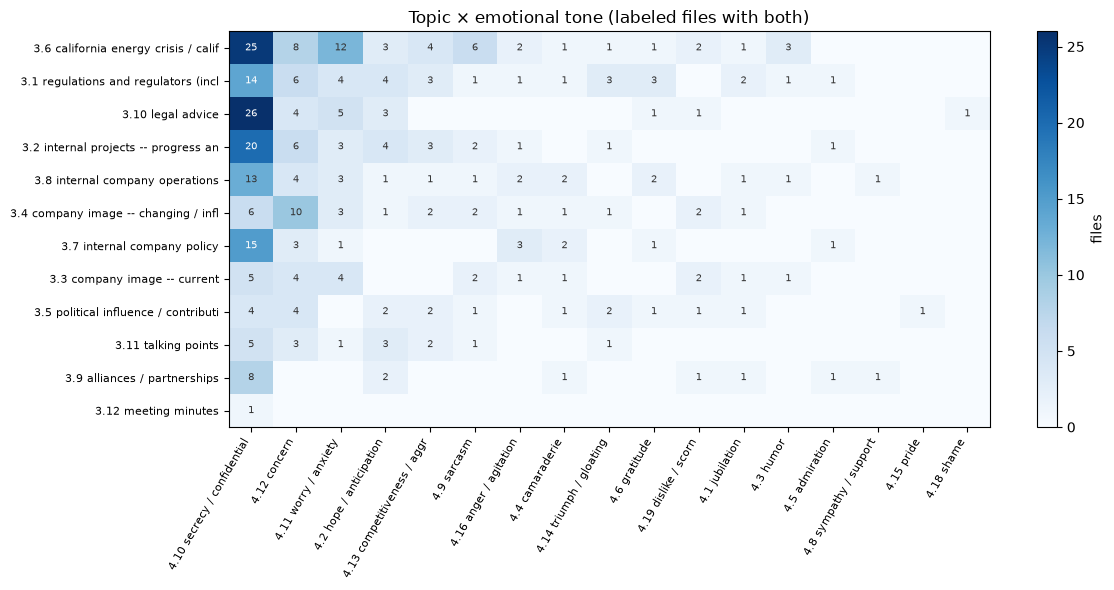

In [20]:
topic = labels[labels["group"] == 3][["berkeley_id", "code", "name"]]
tone = labels[labels["group"] == 4][["berkeley_id", "code", "name"]]
pairs = topic.merge(tone, on="berkeley_id", suffixes=("_topic", "_tone"))
heat = pd.crosstab(pairs["code_topic"] + " " + pairs["name_topic"].str.slice(0, 32),
                   pairs["code_tone"] + " " + pairs["name_tone"].str.slice(0, 22))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(heat.shape[0]), heat.index, fontsize=8)
for (i, j), n in pd.DataFrame(heat.to_numpy()).stack().items():
    if n:
        ax.text(j, i, n, ha="center", va="center", fontsize=7, color="white" if n > heat.to_numpy().max() / 2 else "#333333")
ax.set(title="Topic × emotional tone (labeled files with both)")
fig.colorbar(im, ax=ax, label="files")
plt.tight_layout()
plt.show()

### 8.6 Toward a Jev benchmark

Each category maps naturally to a Jev question. Coarse genre is a **Choice**, and each topic or tone is a yes/no **Noul**. The positives that both annotators chose are a cleaner test set than single-annotator labels, which are better treated as ambiguous and left out. The table counts usable examples per category. Categories with few agreed positives can't give a reliable accuracy number.

In [21]:
# Positives: both annotators chose the category. Ambiguous: only one did (leave out of a test set).
# Negatives: eligible files without the category. Topics only apply to business email (genre 1.1).
all_files = set(labels["berkeley_id"])
business = set(labels.loc[labels["code"] == "1.1", "berkeley_id"])
assigned = labels.groupby("code")["berkeley_id"].agg(set)

rows = []
for r in agreement.itertuples():
    eligible = business if r.code.startswith("3.") else all_files
    rows.append({"group_name": r.group_name, "code": r.code, "name": r.name,
                 "positives": r.agreed, "ambiguous": r.assigned - r.agreed,
                 "negatives": len(eligible - assigned[r.code]), "agreement": f"{r.agreement:.0%}"})
bench = pd.DataFrame(rows)
bench["group_name"] = pd.Categorical(bench["group_name"], GROUP_ORDER, ordered=True)
pd.set_option("display.max_rows", 60)
bench.sort_values(["group_name", "positives"], ascending=[True, False]).reset_index(drop=True)

,group_name,code,name,positives,ambiguous,negatives,agreement
0,coarse genre,1.1,"Company Business, Strategy, etc. (elaborate in Section 3 [Topics])",568,287,847,66%
1,coarse genre,1.4,"Logistic Arrangements (meeting scheduling, technical support, etc)",342,191,1169,64%
2,coarse genre,1.6,Document editing/checking (collaboration),123,53,1526,70%
3,coarse genre,1.3,"Personal but in professional context (e.g., it was good working with you)",70,95,1537,42%
4,coarse genre,1.5,"Employment arrangements (job seeking, hiring, recommendations, etc)",70,26,1606,73%
5,coarse genre,1.2,Purely Personal,27,22,1653,55%
6,coarse genre,1.8,Empty message,16,10,1676,62%
7,coarse genre,1.7,Empty message (due to missing attachment),15,10,1677,60%
8,included/forwarded,2.2,Forwarded email(s) including replies,512,401,789,56%
9,included/forwarded,2.1,Includes new text in addition to forwarded material,345,335,1022,51%


### 8.7 Findings

- **Coverage.** 1,702 labeled files map to 1,658 distinct corpus emails and carry 5,750 labels.
- **The labels are noisy.**
  - Both annotators agreed on 64% of coarse-genre labels, 55% of forwarded-content labels, 52% of topic labels and 51% of tone labels.
  - 207 files (12%) got two or three coarse genres, so the annotators disagreed on the genre itself.
  - 20 emails were labeled more than once (in 64 files). All 20 got different label sets across identical copies.
- **The subset is not representative of the corpus.**
  - 56% of labeled emails come from Steven Kean's mailbox (`kean-s`), which holds 2% of the corpus. `kaminski-v` and `dasovich-j` add another 22%.
  - The labeled emails cluster in mid-2000 and the first half of 2001, during the California crisis. The corpus peaks in late 2001, around the collapse, where the subset has few emails.
- **Content.** The most common topics are the California energy crisis (249 files) and regulation (203). The most common tone by far is secrecy / confidentiality (130 files).
- **As a Jev benchmark.**
  - Only 15 categories have at least 50 positives that both annotators chose: 1.1, 1.4, 1.6, 1.3, 1.5, 2.2, 2.1, 2.13, 2.4, 3.6, 3.1, 3.2, 3.5, 3.8 and 4.10. These are the ones worth evaluating.
  - With agreement around 50–65%, human consistency is a practical ceiling. A disagreement between Jev and a single annotator isn't necessarily a Jev error.
